In [15]:
import numpy as np
import matplotlib.pyplot as plt

import sys
sys.path.append("../..")


from trips.test_problems.Tomography import Tomography
import astra

import jlinops

from pinv import CGWeightedNeumann2DPinvOperatorGPU

from msolver import MMGKS, IASGKS, VanillaGKS

In [29]:
# Define an object of the class Tomogrpahy
Tomo = Tomography ()
# Specify the dimensions of the phantom and the number of angels
nx = 150
ny = 150
n = nx*ny
img_shape = (nx, ny)
views = 100
# Define the true solution throught the function gen_true ().
( x_true , nx , ny ) = Tomo.gen_true( test_problem = "grains", nx = nx , ny = ny)
# Define the forward operator
A = Tomo.forward_Op( nx , ny , views )
# Generate the data
(A , b_true , p , q , AforMatrixOperation ) = Tomo.gen_data( x_true , nx , ny , views )
# Add noise in the true simulated sinogram b_true
(b , delta ) = Tomo.add_noise( b_true = b_true , opt = "Gaussian", noise_level= 0.001)
b_shaped = b.copy()
b = b.flatten()
b_noisy = b.copy()

settings
no crime


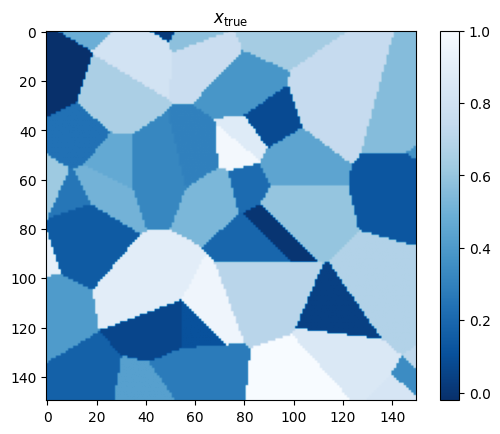

In [30]:
plt.imshow(x_true.reshape((nx,ny)), cmap="Blues_r")
plt.title("$x_{\\text{true}}$")
plt.colorbar()
plt.show()

In [33]:
# plt.imshow(b.res)
# plt.title("$b$")
# plt.show()

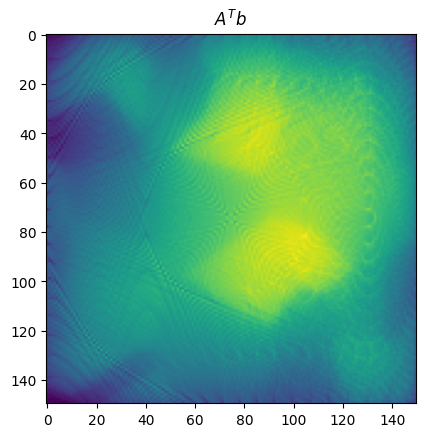

In [ ]:
plt.imshow((A.T @ b.flatten()).reshape((nx,ny)))
plt.title("$A^T b$")
plt.show()

In [32]:
# Set method
method = "dp"

Lmat = jlinops.build_neumann2d_sparse_matrix(img_shape)
L = jlinops.Neumann2D(img_shape)

# # Pseudoinverse factory
# def Lpinv_factory(wr):
#     Ltilde = jlinops.MatrixLinearOperator( sps.diags(wr) @ Lmat)
#     delta = 1e-15
#     for j in range(10):
#         try:
#             return jlinops.BandedCholeskyPinvOperator(Ltilde, delta=delta)
#         except:
#             delta *= 10
#     return None

K = np.ones(n)/np.linalg.norm(np.ones(n))
K = jlinops.MatrixLinearOperator(K)

#L = jlinops.Neumann2D(img_shape)
# def Lpinv_factory(w, *args, **kwargs):
#     return jlinops.CGWeightedNeumann2DPinvOperator(img_shape, weights=w, tol=1e-4, *args, **kwargs)

def Lpinv_factory(w, *args, **kwargs):
    return CGWeightedNeumann2DPinvOperatorGPU(img_shape, weights=w, tol=1e-4, *args, **kwargs)


#err_norm_sq = len(b) # in expectation

q = 1.0
epsilon = 1e-4
weight_params = {
    "q": q,
    "epsilon": epsilon,
}


# Build solvers
noise_var = (delta**2) / len(b.flatten())
img_shape = (nx, ny)
gks_solver = VanillaGKS(A, L, b_noisy, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)
mmgks_solver = MMGKS(A, L, b_noisy, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)


# Misc
AK = A @ K.A
AKpinv = jlinops.QRPinvOperator(AK)
xker = K @ (AKpinv @ b_noisy)

# Run all methods

In [ ]:
vdata = gks_solver.solve(n_iter=50, init_dim=5, x0=None, lambdah0=1e0, lambdah_min=1e-14, lambdah_max=1e7,
                                    regparam=method, x_true=x_true.flatten(), weight_params={},
                                    regparam_kwargs={"eta":1.01})

print("Finished GKS.")


In [21]:
plt.imshow(data["x"].reshape((nx,ny)), cmap="Blues_r")
plt.title("Reconstructed")
plt.show()

NameError: name 'data' is not defined

In [22]:
plt.plot(data["rre_history"])
plt.yscale("log")
plt.title("History of RRE")
plt.ylabel("RRE")
plt.xlabel("iteration index")
plt.show()

NameError: name 'data' is not defined

In [23]:
plt.plot(data["lambda_history"])
plt.yscale("log")
plt.xlabel("iteration index")
plt.ylabel("chosen $\\lambda$")
plt.show()

NameError: name 'data' is not defined

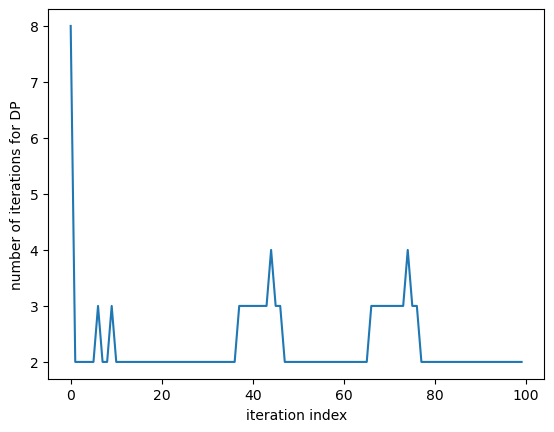

In [36]:
plt.plot(data["dp_cubic_n_iters"])
plt.xlabel("iteration index")
plt.ylabel("number of iterations for DP")
plt.show()

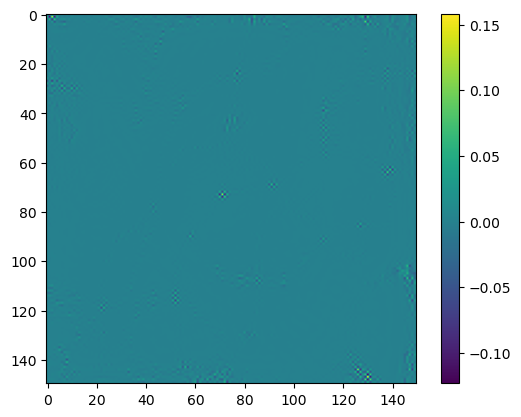

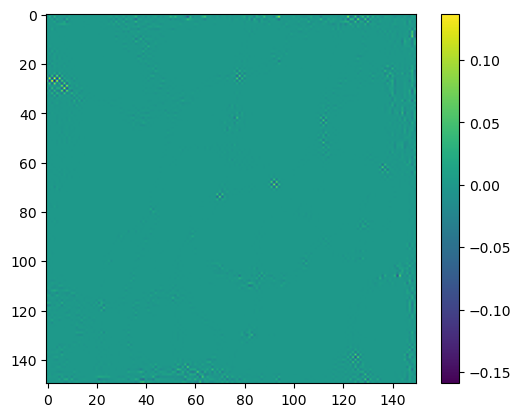

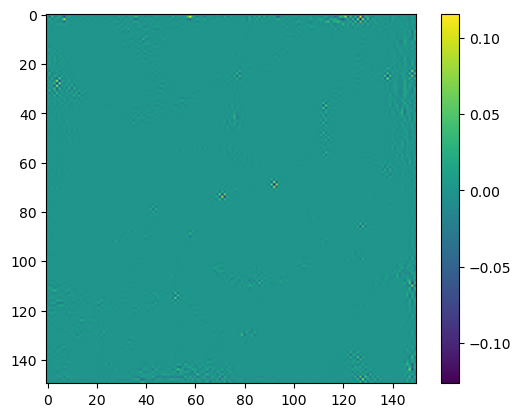

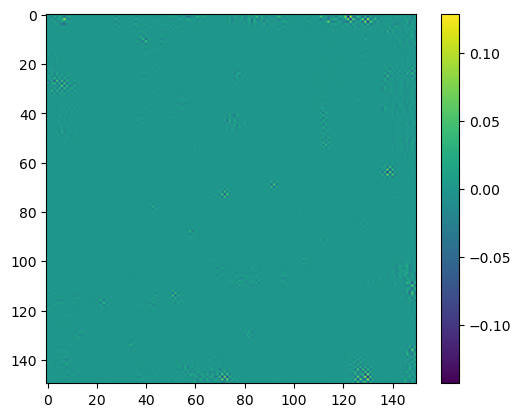

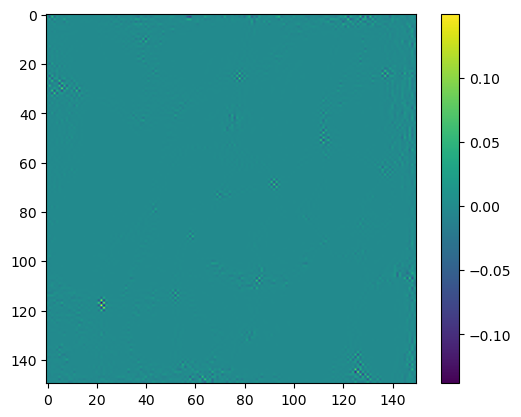

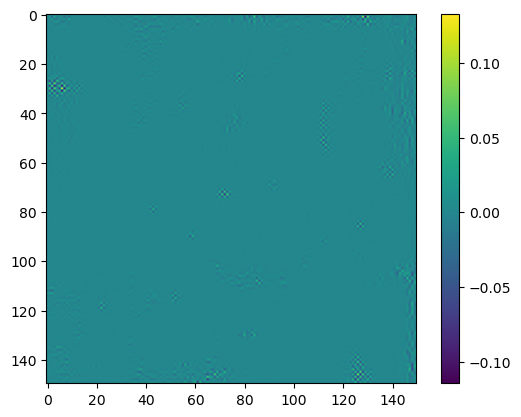

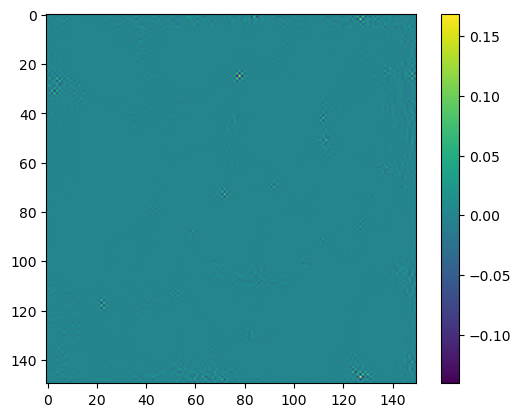

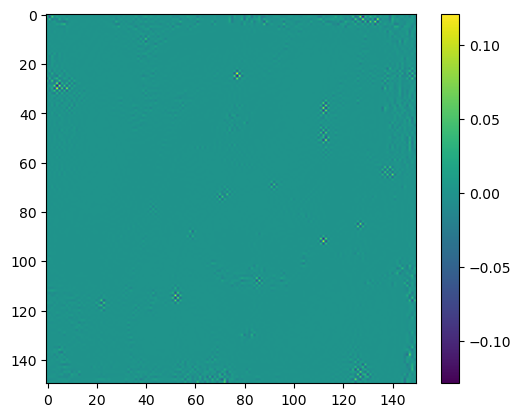

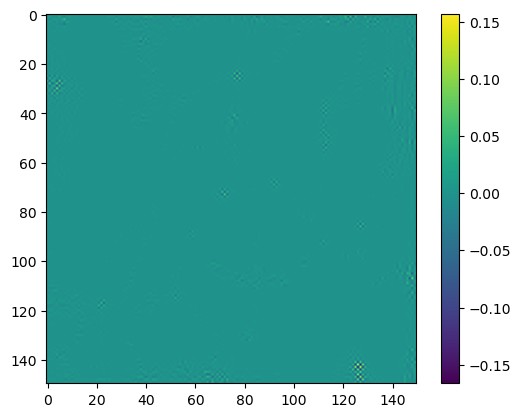

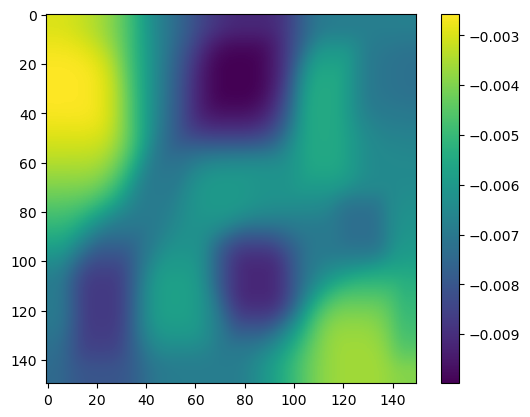

In [37]:
for j in range(10):
    tmp = data["V"][:,j].reshape((nx,ny))
    plt.figure()
    plt.imshow(tmp)
    plt.colorbar()